In [5]:
pip install datasets

   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 7.3 MB/s  0:00:00
   ---------------------------------------- 0.0/838.0 kB ? eta -:--:--
   ---------------------------------------- 838.0/838.0 kB 6.2 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ------------- -------------------------- 1.3/3.8 MB 7.5 MB/s eta 0:00:01
   ------------------------------ --------- 2.9/3.8 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 6.7 MB/s  0:00:00
   ---------------------------------------- 0.0/27.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/27.9 MB 7.4 MB/s eta 0:00:04
   ---- ----------------------------------- 2.9/27.9 MB 7.0 MB/s eta 0:00:04
   ------ --------------------------------- 4.2/27.9 MB 7.2 MB/s eta 0:00:04
   -------- ------------------------------- 5.8/27.9 MB 7.2 MB/s eta 0:00:04
   ---------- ------------------

### Preparing the Dataset

In [13]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("ashraq/fashion-product-images-small")

In [ ]:
products_df = pd.DataFrame(ds["train"])


In [17]:
products_df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,<PIL.Image.Image image mode=L size=60x80 at 0x...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,<PIL.Image.Image image mode=RGB size=60x80 at ...


In [16]:
products_df.shape

(44072, 11)

In [22]:
products_df.columns.tolist()

['id',
 'gender',
 'masterCategory',
 'subCategory',
 'articleType',
 'baseColour',
 'season',
 'year',
 'usage',
 'productDisplayName',
 'image']

In [20]:
%pip install requests


   ---------------------------------------- 0/4 [urllib3]
   ------------------------------ --------- 3/4 [requests]
   ---------------------------------------- 4/4 [requests]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# not that many
from datasets import load_dataset
import requests
from PIL import Image
import pandas as pd
from pathlib import Path
 
# Load dataset from HuggingFace
print("Loading product dataset...")
try:
    # Try loading the dataset
    dataset = load_dataset("ashraq/fashion-product-images-small", split="train[:100]")  # First 100 samples
    print(f"✓ Loaded {len(dataset)} products")
    
    # Convert to pandas for easier manipulation
    products_df = pd.DataFrame(dataset)
    print(f"Dataset columns: {products_df.columns.tolist()}")
    
except Exception as e:
    print(f"⚠ Could not load HuggingFace dataset: {e}")
    print("Using local images instead...")
    
    # Alternative: Use local images
    # Create a products.json file with product information
    products_data = [
        {
            "id": 1,
            "name": "Wireless Headphones",
            "price": 79.99,
            "category": "Electronics",
            "image_path": "images/product1.jpg"
        },
        # Add more products...
    ]
    
    products_df = pd.DataFrame(products_data)
 
# Create images directory
images_dir = Path("product_images")
images_dir.mkdir(exist_ok=True)
 
print(f"\n✓ Dataset prepared!")
print(f"  Total products: {len(products_df)}")

Loading product dataset...
✓ Loaded 100 products
Dataset columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image']

✓ Dataset prepared!
  Total products: 100


In [23]:
products_df

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,<PIL.Image.Image image mode=L size=60x80 at 0x...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,<PIL.Image.Image image mode=RGB size=60x80 at ...
...,...,...,...,...,...,...,...,...,...,...,...
95,55802,Women,Apparel,Loungewear and Nightwear,Night suits,White,Summer,2017.0,Casual,SDL by Sweet Dreams Women Green Printed Night ...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
96,29584,Men,Apparel,Topwear,Tshirts,Black,Summer,2012.0,Casual,Indigo Nation Men Printed Black T-shirt,<PIL.JpegImagePlugin.JpegImageFile image mode=...
97,43967,Women,Personal Care,Fragrance,Perfume and Body Mist,Red,Spring,2017.0,Casual,DKNY Women Red Delicious Perfume,<PIL.Image.Image image mode=RGB size=60x80 at ...
98,28456,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2012.0,Sports,Urban Yoga Women Blue Skirt With Leggings,<PIL.Image.Image image mode=RGB size=60x80 at ...


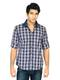

In [28]:
products_df.iloc[0]["image"]

### Encoding Images for API


In [33]:
import base64
from io import BytesIO
from PIL import Image

def encode_image_to_base64(image):
    """Encode a PIL image or an image file path to a base64 string."""
    if isinstance(image, Image.Image):
        buffer = BytesIO()
        image.save(buffer, format=image.format or "JPEG")
        data = buffer.getvalue()
    else:  # treat it as a file path
        with open(image, "rb") as f:
            data = f.read()
    return base64.b64encode(data).decode("utf-8")

# Example usage
sample_image = products_df.iloc[0]["image"]
encoded_image = encode_image_to_base64(sample_image)
print(f"Encoded image length: {len(encoded_image)} characters")
print(f"Encoded prefix: {encoded_image[:40]}...")


Encoded image length: 2388 characters
Encoded prefix: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcG...


### Creating the Product Listing Prompt

In [35]:
def create_product_listing_prompt(product_name, price, category, additional_info=None):
    """
    Create a prompt for generating product listings.
    
    Parameters:
    - product_name: Name of the product
    - price: Price of the product
    - category: Product category
    - additional_info: Optional additional information
    
    Returns:
    - Formatted prompt string
    """
    prompt = f"""You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.
 
Product Information:
- Name: {product_name}
- Price: ${price:.2f}
- Category: {category}
{f'- Additional Info: {additional_info}' if additional_info else ''}
 
Please create a professional product listing that includes:
 
1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive language
   - Include relevant details visible in the image
3. **Key Features** (bullet points, 5-7 items)
4. **SEO Keywords** (comma-separated, 10-15 relevant keywords)
 
Format your response as JSON with the following structure:
{{
    "title": "Product title here",
    "description": "Full description here",
    "features": ["Feature 1", "Feature 2", ...],
    "keywords": "keyword1, keyword2, ..."
}}
 
Be specific about what you see in the image. Mention colors, materials, design elements, and any distinctive features."""
    
    return prompt
 
# Test prompt creation
test_prompt = create_product_listing_prompt(
    product_name="Wireless Bluetooth Headphones",
    price=79.99,
    category="Electronics",
    additional_info="Noise cancelling, 30-hour battery"
)
 
print("\n" + "="*50)
print("PROMPT TEMPLATE")
print("="*50)
print(test_prompt[:500] + "...")  # Show first 500 characters


PROMPT TEMPLATE
You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.

Product Information:
- Name: Wireless Bluetooth Headphones
- Price: $79.99
- Category: Electronics
- Additional Info: Noise cancelling, 30-hour battery

Please create a professional product listing that includes:

1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive ...


### Step 5: Calling the ChatGPT API with Vision


In [ ]:
import os
import json

from openai import OpenAI
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))  # reads OPENAI_API_KEY from your environment

response = client.responses.create(
    model="gpt-4o-mini",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_text", "text": "Describe this product."},
            {"type": "input_image", "image_url": f"data:image/jpeg;base64,{encoded_image}"},
        ],
    }],
    #text={"format": {"type": "json_object"}},   # forces plain, valid JSON with no code fences

)
print(response.output_text)


This product is a men's shirt featuring a plaid pattern. It has a button-up front and a collar, with short sleeves for a casual look. The color scheme includes a mix of darker and lighter shades, making it versatile for various occasions. The shirt is likely made from a comfortable fabric, suitable for everyday wear. Its casual style makes it a great option for relaxed outings or informal gatherings.


In [45]:
import json
from openai import OpenAI

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

row = products_df.iloc[0]
prompt = create_product_listing_prompt(
    product_name=row["productDisplayName"],
    price=29.99,
    category=row["articleType"],
)

response = client.responses.create(
    model="gpt-4o-mini",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_text", "text": prompt},   # <- your JSON prompt, not "Describe this product."
            {"type": "input_image", "image_url": f"data:image/jpeg;base64,{encoded_image}"},
        ],
    }],
    text={"format": {"type": "json_object"}},          # <- uncommented
)

listing = json.loads(response.output_text)              # <- the actual parsing step
missing = {"title", "description", "features", "keywords"} - listing.keys()
print("✓ JSON parsed correctly" if not missing else f"✗ Missing keys: {missing}")
print(json.dumps(listing, indent=2))


✓ JSON parsed correctly
{
  "title": "Stylish Turtle Check Men\u2019s Navy Blue Shirt - $29.99",
  "description": "Elevate your wardrobe with the Turtle Check Men's Navy Blue Shirt, designed for both comfort and style. Crafted from high-quality cotton, this shirt features a classic check pattern that effortlessly blends sophistication and casual flair. The navy blue background accentuates the vibrant check design, making it a versatile choice for any occasion\u2014whether you're going out for brunch or heading to the office. The short-sleeve cut ensures breathability during warmer months, while the tailored fit flatters any silhouette. Pair it with jeans or chinos for an unbeatable look that speaks of confidence and taste. With a focus on durability, this shirt can be a staple in your collection for years to come. Grab yours today at just $29.99!",
  "features": [
    "Premium cotton material for all-day comfort",
    "Breathable short sleeves for warmer weather",
    "Timeless navy bl

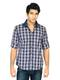

In [41]:
sample_image

### Processing Multiple Products


In [40]:
products_df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,<PIL.Image.Image image mode=L size=60x80 at 0x...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,<PIL.Image.Image image mode=RGB size=60x80 at ...


In [48]:
import json
import time
from pathlib import Path
import pandas as pd

REQUIRED_KEYS = {"title", "description", "features", "keywords"}

def generate_listing(row, price=29.99, model="gpt-4o-mini"):
    """Generate a product listing (as a dict) for one product row."""
    image = row["image"]
    if image.mode not in ("RGB", "L"):        # e.g. RGBA/P images can't be saved as JPEG
        image = image.convert("RGB")
    encoded = encode_image_to_base64(image)

    prompt = create_product_listing_prompt(
        product_name=row["productDisplayName"],
        price=price,
        category=row["articleType"],
        additional_info=f"Colour: {row['baseColour']}, Gender: {row['gender']}, Usage: {row['usage']}",
    )

    response = client.responses.create(
        model=model,
        input=[{
            "role": "user",
            "content": [
                {"type": "input_text", "text": prompt},
                {"type": "input_image", "image_url": f"data:image/jpeg;base64,{encoded}"},
            ],
        }],
        text={"format": {"type": "json_object"}},
    )

    listing = json.loads(response.output_text)
    missing = REQUIRED_KEYS - listing.keys()
    if missing:
        raise ValueError(f"Missing keys in response: {missing}")
    return listing


def process_products(products_df, n=5, delay=0.5):
    """Generate listings for the first n products. Errors are recorded, not raised."""
    results, errors = [], []

    for i, (_, row) in enumerate(products_df.head(n).iterrows(), start=1):
        name = row["productDisplayName"]
        print(f"[{i}/{n}] {name} ... ", end="")
        try:
            listing = generate_listing(row)
            results.append({
                "id": row["id"],
                "product_name": name,
                "category": row["articleType"],
                "title": listing["title"],
                "description": listing["description"],
                "features": listing["features"],
                "keywords": listing["keywords"],
            })
            print("✓")
        except Exception as e:                 # one bad product shouldn't stop the batch
            errors.append({"id": row["id"], "product_name": name, "error": f"{type(e).__name__}: {e}"})
            print(f"✗ {type(e).__name__}")
        time.sleep(delay)                      # be gentle with rate limits

    return results, errors


results, errors = process_products(products_df, n=5)

# --- Save results ---
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "listings.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False, default=str)

results_df = pd.DataFrame(results)
if not results_df.empty:
    results_df.assign(features=results_df["features"].apply(" | ".join)) \
              .to_csv(output_dir / "listings.csv", index=False)

if errors:
    pd.DataFrame(errors).to_csv(output_dir / "errors.csv", index=False)

print(f"\nDone: {len(results)} succeeded, {len(errors)} failed")
print(f"Saved to {output_dir.resolve()}")


[1/5] Turtle Check Men Navy Blue Shirt ... ✓
[2/5] Peter England Men Party Blue Jeans ... ✓
[3/5] Titan Women Silver Watch ... ✓
[4/5] Manchester United Men Solid Black Track Pants ... ✓
[5/5] Puma Men Grey T-shirt ... ✓

Done: 5 succeeded, 0 failed
Saved to C:\Users\tscho\OneDrive\Desktop\Ironhack course\Week1\Day4\openai-python\output
